> **Versão pública (2026).** Notebook original, executado em 2021 no Windows (Python 3.7, Anaconda), com as bibliotecas na mesma pasta. As saídas são as originais. Para rodar de novo, veja o [README desta pasta](README.md).

In [1]:
import pandas as pd
import numpy as np
import time

from IPython.display import display
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedShuffleSplit, ShuffleSplit
from sklearn.model_selection import StratifiedKFold, KFold

######################

import AleTransforms as trf
import AleDatasetAnalysis as dsa

import AleLearners as lrn
import AleMLAnalysis as aml

import AleExplainers as exp

In [2]:
import importlib

importlib.reload(trf)
importlib.reload(dsa)

importlib.reload(lrn)
importlib.reload(aml)

importlib.reload(exp)

<module 'AleExplainers' from '<PASTA_DAS_BIBLIOTECAS>\\AleExplainers.py'>

In [3]:
df = pd.read_csv('datasets/train_house.csv')

In [4]:
df

Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0        1          60       RL         65.0     8450   Pave   NaN      Reg   
1        2          20       RL         80.0     9600   Pave   NaN      Reg   
2        3          60       RL         68.0    11250   Pave   NaN      IR1   
3        4          70       RL         60.0     9550   Pave   NaN      IR1   
4        5          60       RL         84.0    14260   Pave   NaN      IR1   
...    ...         ...      ...          ...      ...    ...   ...      ...   
1455  1456          60       RL         62.0     7917   Pave   NaN      Reg   
1456  1457          20       RL         85.0    13175   Pave   NaN      Reg   
1457  1458          70       RL         66.0     9042   Pave   NaN      Reg   
1458  1459          20       RL         68.0     9717   Pave   NaN      Reg   
1459  1460          20       RL         75.0     9937   Pave   NaN      Reg   

     LandContour Utilities  ... PoolArea PoolQC  Fence MiscFeature MiscVal  \
0            Lvl    AllPub  ...        0    NaN    NaN         NaN       0   
1            Lvl    AllPub  ...        0    NaN    NaN         NaN       0   
2            Lvl    AllPub  ...        0    NaN    NaN         NaN       0   
3            Lvl    AllPub  ...        0    NaN    NaN         NaN       0   
4            Lvl    AllPub  ...        0    NaN    NaN         NaN       0   
...          ...       ...  ...      ...    ...    ...         ...     ...   
1455         Lvl    AllPub  ...        0    NaN    NaN         NaN       0   
1456         Lvl    AllPub  ...        0    NaN  MnPrv         NaN       0   
1457         Lvl    AllPub  ...        0    NaN  GdPrv        Shed    2500   
1458         Lvl    AllPub  ...        0    NaN    NaN         NaN       0   
1459         Lvl    AllPub  ...        0    NaN    NaN         NaN       0   

     MoSold YrSold  SaleType  SaleCondition  SalePrice  
0         2   2008        WD         Normal     208500  
1         5   2007        WD         Normal     181500  
2         9   2008        WD         Normal     223500  
3         2   2006        WD        Abnorml     140000  
4        12   2008        WD         Normal     250000  
...     ...    ...       ...            ...        ...  
1455      8   2007        WD         Normal     175000  
1456      2   2010        WD         Normal     210000  
1457      5   2010        WD         Normal     266500  
1458      4   2010        WD         Normal     142125  
1459      6   2008        WD         Normal     147500  

[1460 rows x 81 columns]

In [5]:
df.dtypes[df.dtypes == 'O']

MSZoning         object
Street           object
Alley            object
LotShape         object
LandContour      object
Utilities        object
LotConfig        object
LandSlope        object
[... 28 linhas omitidas na versão pública ...]
GarageCond       object
PavedDrive       object
PoolQC           object
Fence            object
MiscFeature      object
SaleType         object
SaleCondition    object
dtype: object

In [6]:
df.dtypes[df.dtypes != 'O']

Id                 int64
MSSubClass         int64
LotFrontage      float64
LotArea            int64
OverallQual        int64
OverallCond        int64
YearBuilt          int64
YearRemodAdd       int64
MasVnrArea       float64
BsmtFinSF1         int64
BsmtFinSF2         int64
BsmtUnfSF          int64
TotalBsmtSF        int64
1stFlrSF           int64
2ndFlrSF           int64
LowQualFinSF       int64
GrLivArea          int64
BsmtFullBath       int64
BsmtHalfBath       int64
FullBath           int64
HalfBath           int64
BedroomAbvGr       int64
KitchenAbvGr       int64
TotRmsAbvGrd       int64
Fireplaces         int64
GarageYrBlt      float64
GarageCars         int64
GarageArea         int64
WoodDeckSF         int64
OpenPorchSF        int64
EnclosedPorch      int64
3SsnPorch          int64
ScreenPorch        int64
PoolArea           int64
MiscVal            int64
MoSold             int64
YrSold             int64
SalePrice          int64
dtype: object

In [7]:
df_nulls = pd.DataFrame(df.isnull().sum(), columns = ['QTD'])
df_nulls = df_nulls[df_nulls['QTD'] > 0]
df_nulls = df_nulls.sort_values('QTD', ascending = True)
display(df_nulls)

QTD
Electrical       1
MasVnrType       8
MasVnrArea       8
BsmtQual        37
BsmtCond        37
BsmtFinType1    37
BsmtExposure    38
BsmtFinType2    38
GarageCond      81
GarageQual      81
GarageFinish    81
GarageType      81
GarageYrBlt     81
LotFrontage    259
FireplaceQu    690
Fence         1179
Alley         1369
MiscFeature   1406
PoolQC        1453

In [8]:
colunas_id = ['Id']
alvo = 'SalePrice'

# Regressor

In [9]:
vars_cat = list(df.dtypes[df.dtypes == 'O'].index)
vars_num = [v for v in list(df.dtypes[df.dtypes != 'O'].index) if v not in colunas_id and v not in alvo]

In [10]:
frac_teste = 0.2

ss_teste = ShuffleSplit(n_splits = 1, test_size = frac_teste, random_state = 42)
split_teste = list(ss_teste.split(df.values, df[alvo].values))[0] 

df_intermed = df.iloc[split_teste[0]]
df_teste = df.iloc[split_teste[1]]

In [11]:
tratador = trf.TrataDataset(df_intermed, num_div = None, num_cat = 3, 
                            features_numericas = vars_num,
                            features_categoricas = vars_cat)
tratador.cria_one_hot_encoder(df_intermed, considera_resto = True, usar_str = True)

df_intermed_t = tratador.aplica_transformacao_ohe(df_intermed, usar_ponto_medio = True)

In [12]:
frac_val = 0.2
num_splits = 4

ss = ShuffleSplit(n_splits = num_splits, test_size = frac_val, random_state = 42)
lista_splits = list(ss.split(df_intermed.values, df_intermed[alvo].values))  

In [13]:
dict_Xy = {}

i = 0
for par in lista_splits:
    df_treino = df_intermed.iloc[par[0]]
    df_val = df_intermed.iloc[par[1]]
    
    df_treino_t = tratador.aplica_transformacao_ohe(df_treino, usar_ponto_medio = True)
    df_val_t = tratador.aplica_transformacao_ohe(df_val, usar_ponto_medio = True)
    
    dict_Xy.update({'Treino_' + str(2*i + 1): (df_treino_t.drop(colunas_id, axis = 1).drop(alvo, axis = 1), df_treino_t[alvo]),
               'Treino_' + str(2*i + 2): (df_val_t.drop(colunas_id, axis = 1).drop(alvo, axis = 1), df_val_t[alvo])})
    
    i = i + 1

Checando Datasets
Filtrando Features sem Variância
Criando a Expansão em Série
Número de Parâmetros da Expansão: 175
Calculando as Normalizações das Features
Número de Parâmetros: 175
Normalizando o Alvo
Criando o Baseline Constante
Inicializando os Parâmetros para Fitting
31.70257043838501


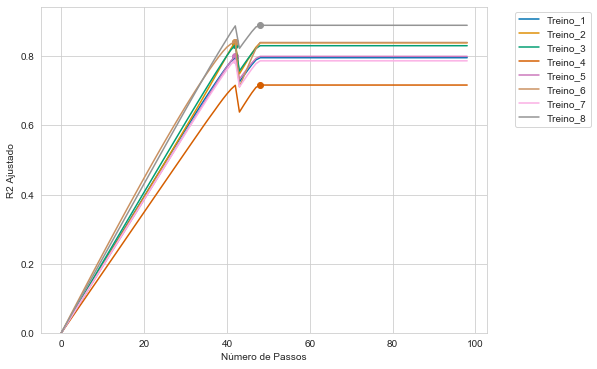

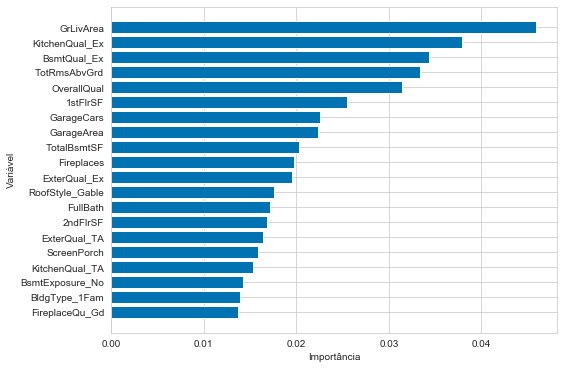

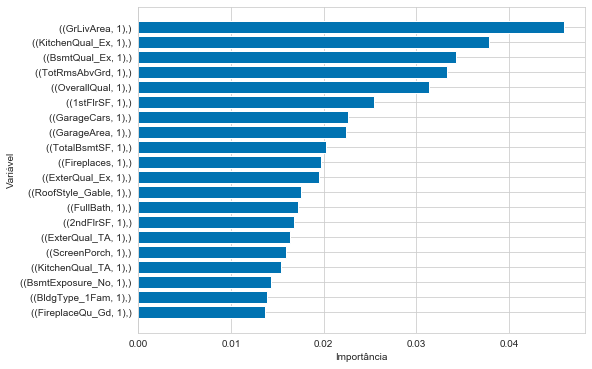

In [14]:
t = time.time()

rgs = lrn.SeriesMultiGradientRegressor()
rgs.setup_datasets(dict_Xy, laurent = False, ordem = 1, apenas_interacoes = False)
rgs.setup_optimizer(alpha = 0.01, epsilon = 1e-6, early_stop = 50, filtro_atualizacao_thetas = True)
rgs.fit(num_passos = 1000, verbose = 0, plot = False)

print(time.time() - t)

rgs.grafico_vies_variancia(ymin = 0)
rgs.grafico_importancias(num_vars = 20)
rgs.grafico_importancias_termos(num_vars = 20)

In [15]:
df_intermed_t = tratador.aplica_transformacao_ohe(df_intermed, usar_ponto_medio = True)
df_teste_t = tratador.aplica_transformacao_ohe(df_teste, usar_ponto_medio = True)
    
preds_intermed = rgs.predict(df_intermed_t.drop(colunas_id, axis = 1).drop(alvo, axis = 1))
preds_teste = rgs.predict(df_teste_t.drop(colunas_id, axis = 1).drop(alvo, axis = 1))

Treino         Teste
QTD                    1200.0         290.0
Soma_Alvo         210000000.0    52000000.0
Soma_Pred         210000000.0    52000000.0
Media_Alvo           180000.0      180000.0
Media_Pred           180000.0      180000.0
MAE                   21000.0       23000.0
MSE              1200000000.0  1300000000.0
RMSE                  34000.0       36000.0
RAE                      0.37          0.37
RSE                      0.19          0.17
RRSE                     0.44          0.42
RAE_ref                  0.37          0.36
RSE_ref                  0.19          0.17
RRSE_ref                 0.44          0.42
R1                       0.63          0.63
R2                       0.81          0.83
RR2                      0.56          0.58
R1_ref                   0.63          0.64
R2_ref                   0.81          0.83
RR2_ref                  0.56          0.58
KendallTau_Conc          0.92           0.7
KendallTau_Disc         0.082           0.3
KendallTau               0.84           0.4
KS                      0.086         0.099
Coef_KS                   0.3          0.26
Coef_KS_ref               0.3          0.38

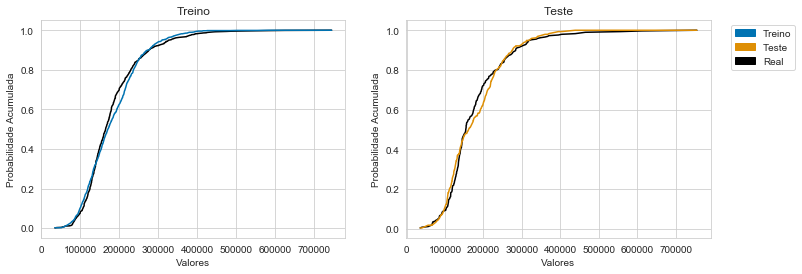

In [16]:
df_intermed_aval = df_intermed.copy()
df_teste_aval = df_teste.copy()

df_intermed_aval['Pred'] = preds_intermed
df_teste_aval['Pred'] = preds_teste

dict_dfs = {'Treino': df_intermed_aval,
            'Teste': df_teste_aval}
avaliacaorgs = aml.AvaliaDatasetsRegressao(dict_dfs, 
                                               alvo, 
                                               'Pred', 
                                               num_kendalltau = 10000, 
                                               num_div = 10, 
                                               num_cat = 3, 
                                               unit = None, 
                                               chave_treino = 'Treino')

display(avaliacaorgs.valor_metricas(alga_signif = 2, conv_str = True))

avaliacaorgs.grafico_distribuicao_acumulada()

In [19]:
N = 20
discretizador = lrn.DiscretizaAlvoRegressivo(df_intermed[alvo].values, N)

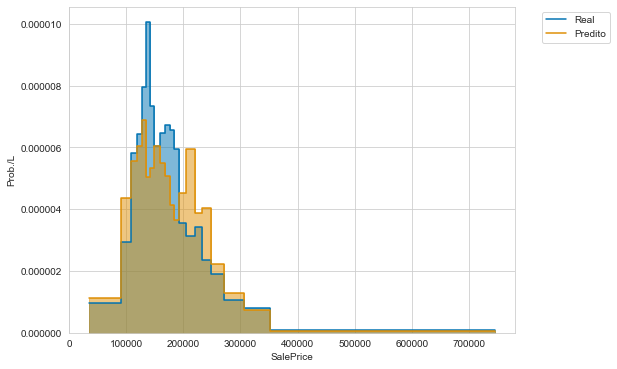

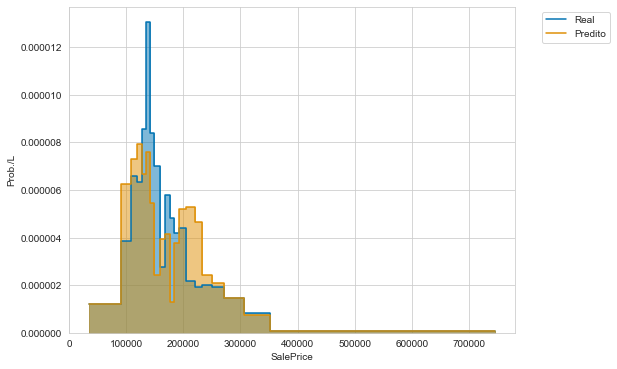

In [23]:
paleta_cores = sns.color_palette("colorblind")
with sns.axes_style("whitegrid"):
    fig, axs = plt.subplots(1, 1, figsize = [8, 6])

    x, y = discretizador.curva_distribuicao_probabilidade(discretizador.calcula_probabilidades(df_intermed[alvo].values))
    axs.plot(x, y, color = paleta_cores[0], label = 'Real')
    axs.fill_between(x, y, color = paleta_cores[0], alpha = 0.5)
    
    x, y = discretizador.curva_distribuicao_probabilidade(discretizador.calcula_probabilidades(preds_intermed))
    axs.plot(x, y, color = paleta_cores[1], label = 'Predito')
    axs.fill_between(x, y, color = paleta_cores[1], alpha = 0.5)
    
    axs.set_ylim(bottom = 0.0)
    axs.set_xlabel(alvo)
    axs.set_ylabel('Prob./L')
    axs.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.show()

paleta_cores = sns.color_palette("colorblind")
with sns.axes_style("whitegrid"):
    fig, axs = plt.subplots(1, 1, figsize = [8, 6])

    x, y = discretizador.curva_distribuicao_probabilidade(discretizador.calcula_probabilidades(df_teste[alvo].values))
    axs.plot(x, y, color = paleta_cores[0], label = 'Real')
    axs.fill_between(x, y, color = paleta_cores[0], alpha = 0.5)
    
    x, y = discretizador.curva_distribuicao_probabilidade(discretizador.calcula_probabilidades(preds_teste))
    axs.plot(x, y, color = paleta_cores[1], label = 'Predito')
    axs.fill_between(x, y, color = paleta_cores[1], alpha = 0.5)
    
    axs.set_ylim(bottom = 0.0)
    axs.set_xlabel(alvo)
    axs.set_ylabel('Prob./L')
    axs.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.show()

# Classificadores

In [25]:
discretizador.intervalos.info_discretizacao()

QTD       Min       Max      Meio               Str
0    63   34900.0   90675.0   62787.5    [34900, 90700)
1    64   90675.0  109250.0   99962.5   [90700, 109000)
2    67  109250.0  119100.0  114175.0  [109000, 119000)
3    65  119100.0  127750.0  123425.0  [119000, 128000)
4    67  127750.0  134950.0  131350.0  [128000, 135000)
5    74  134950.0  141250.0  138100.0  [135000, 141000)
6    70  141250.0  149425.0  145337.5  [141000, 149000)
7    69  149425.0  159217.0  154321.0  [149000, 159000)
8    66  159217.0  167950.0  163583.5  [159000, 168000)
9    65  167950.0  176216.0  172083.0  [168000, 176000)
10   60  176216.0  184050.0  180133.0  [176000, 184000)
11   57  184050.0  192250.0  188150.0  [184000, 192000)
12   55  192250.0  205475.0  198862.5  [192000, 205000)
13   52  205475.0  219750.0  212612.5  [205000, 220000)
14   50  219750.0  232300.0  226025.0  [220000, 232000)
15   47  232300.0  249300.0  240800.0  [232000, 249000)
16   47  249300.0  270500.0  259900.0  [249000, 270000)
17   44  270500.0  305950.0  288225.0  [270000, 306000)
18   43  305950.0  352000.0  328975.0  [306000, 352000)
19   43  352000.0  745000.0  548500.0  [352000, 745000)

Checando Datasets
Filtrando Features sem Variância
Criando a Expansão em Série
Número de Parâmetros da Expansão: 175
Calculando as Normalizações das Features
Número de Parâmetros: 175
Criando o Baseline Constante
Inicializando os Parâmetros para Fitting
10.211412191390991


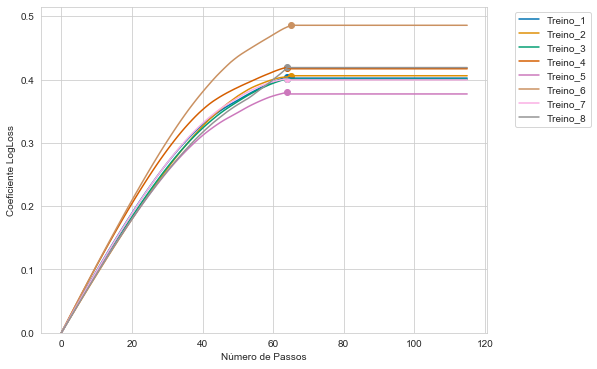

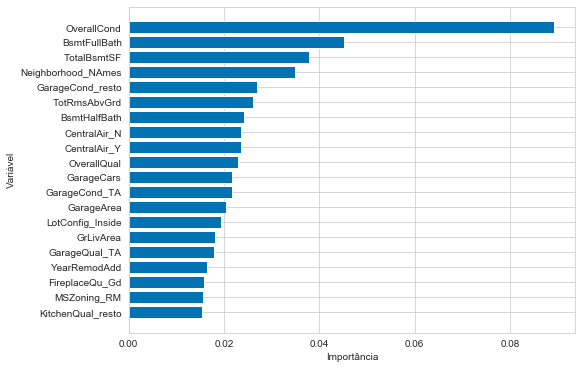

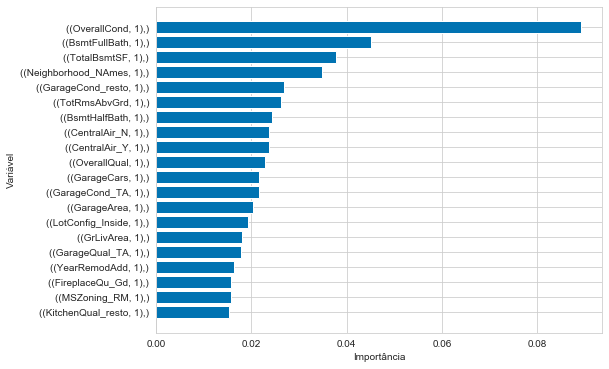

Checando Datasets
Filtrando Features sem Variância
Criando a Expansão em Série
Número de Parâmetros da Expansão: 175
Calculando as Normalizações das Features
Número de Parâmetros: 175
Criando o Baseline Constante
Inicializando os Parâmetros para Fitting
5.501147747039795


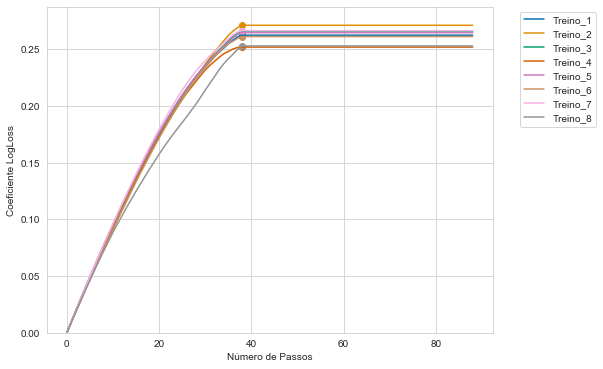

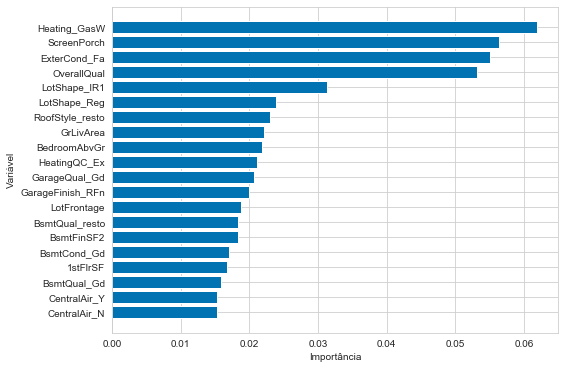

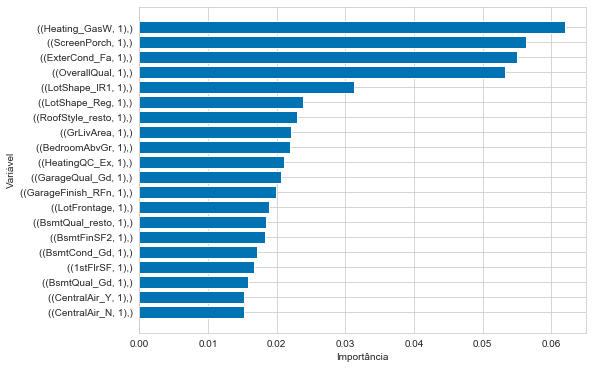

Checando Datasets
Filtrando Features sem Variância
Criando a Expansão em Série
Número de Parâmetros da Expansão: 175
Calculando as Normalizações das Features
Número de Parâmetros: 175
Criando o Baseline Constante
Inicializando os Parâmetros para Fitting
6.121046543121338


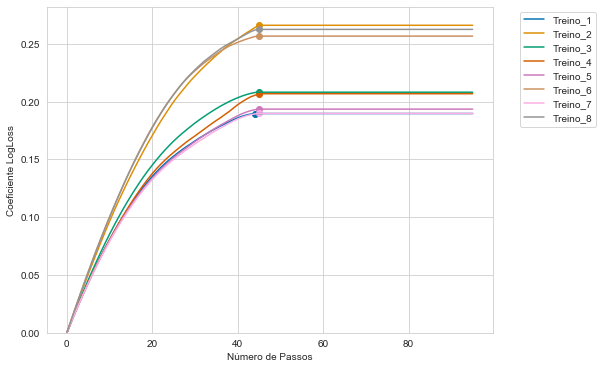

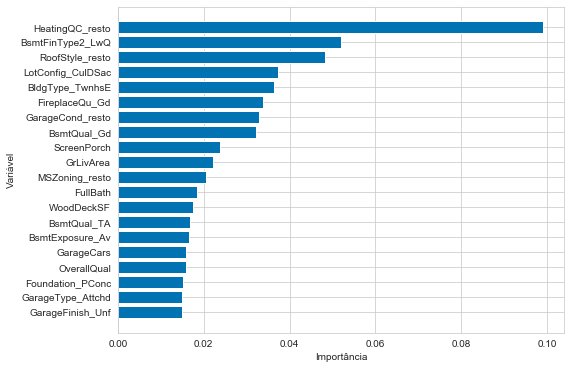

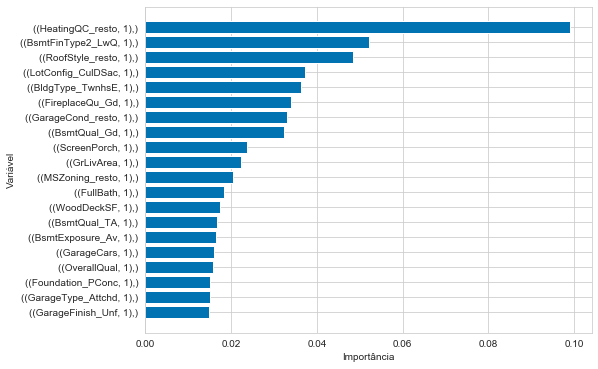

Checando Datasets
Filtrando Features sem Variância
Criando a Expansão em Série
Número de Parâmetros da Expansão: 175
Calculando as Normalizações das Features
Número de Parâmetros: 175
Criando o Baseline Constante
Inicializando os Parâmetros para Fitting
5.403160810470581


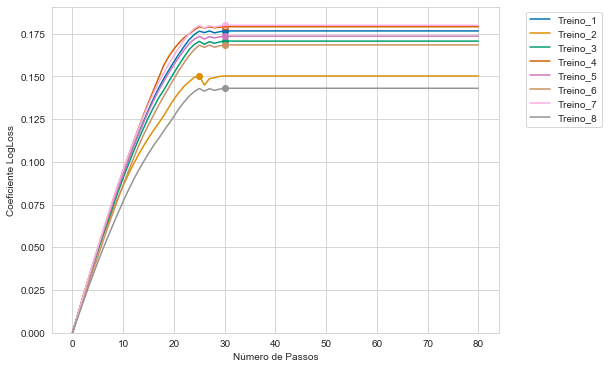

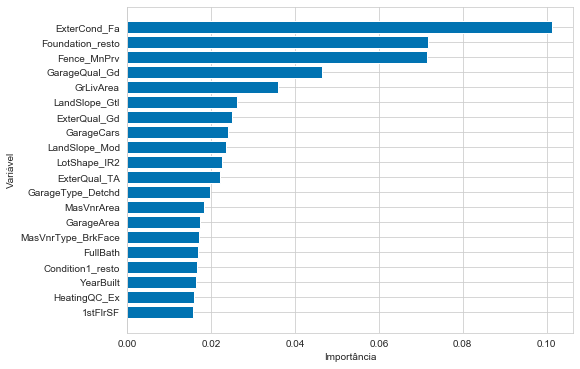

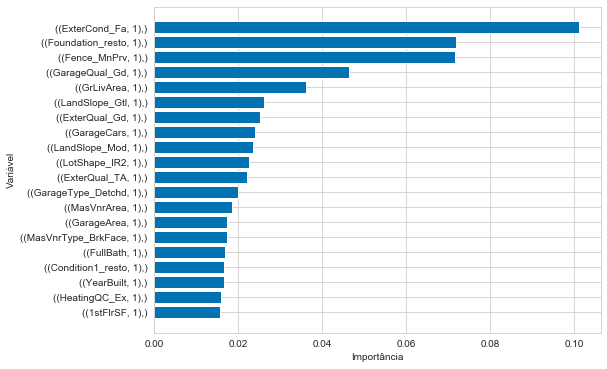

Checando Datasets
Filtrando Features sem Variância
Criando a Expansão em Série
Número de Parâmetros da Expansão: 175
Calculando as Normalizações das Features
Número de Parâmetros: 175
Criando o Baseline Constante
Inicializando os Parâmetros para Fitting
4.677273511886597


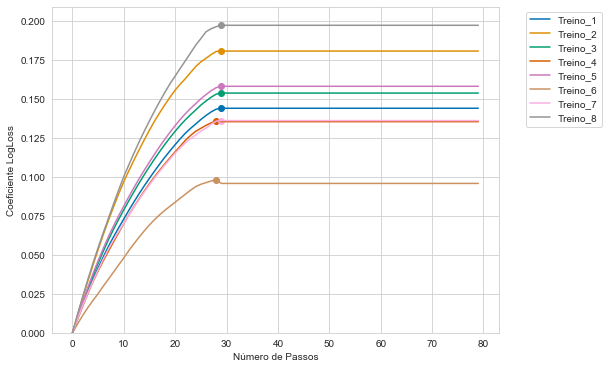

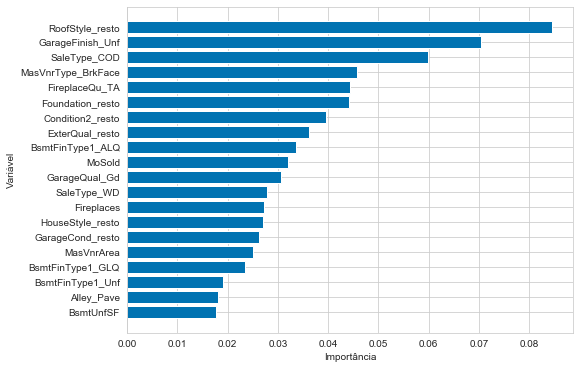

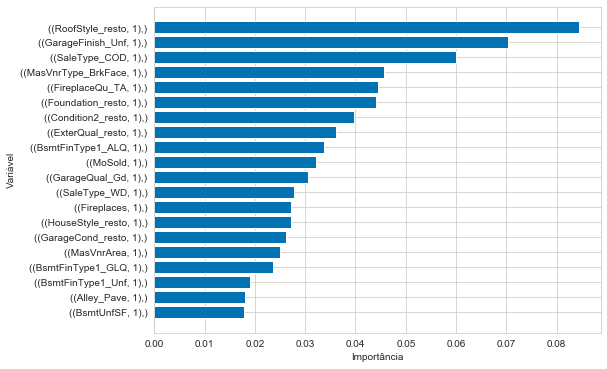

Checando Datasets
Filtrando Features sem Variância
Criando a Expansão em Série
Número de Parâmetros da Expansão: 175
Calculando as Normalizações das Features
Número de Parâmetros: 175
Criando o Baseline Constante
Inicializando os Parâmetros para Fitting
4.120362997055054


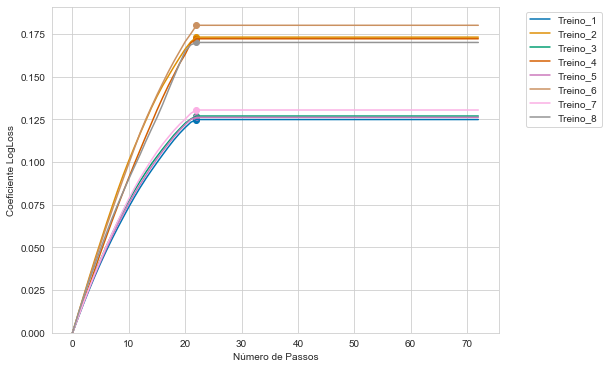

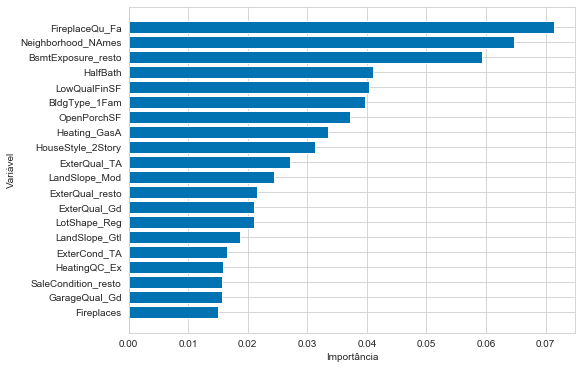

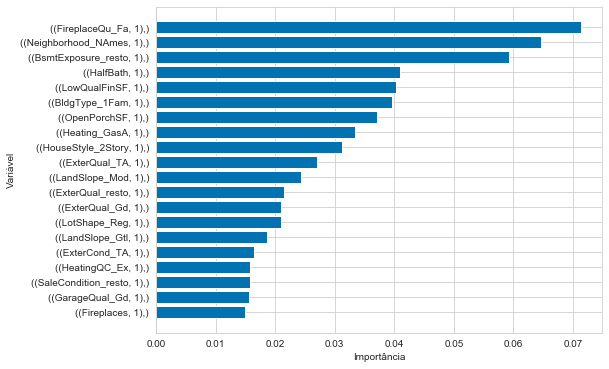

Checando Datasets
Filtrando Features sem Variância
Criando a Expansão em Série
Número de Parâmetros da Expansão: 175
Calculando as Normalizações das Features
Número de Parâmetros: 175
Criando o Baseline Constante
Inicializando os Parâmetros para Fitting
5.119201898574829


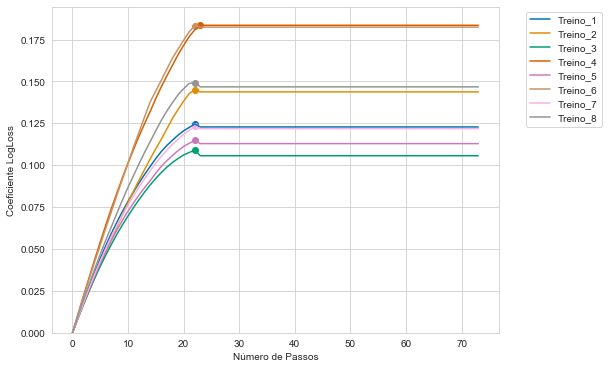

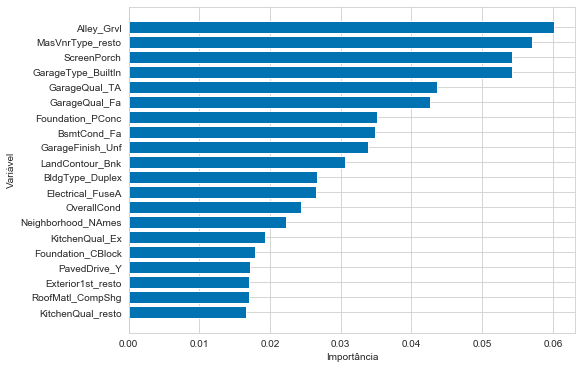

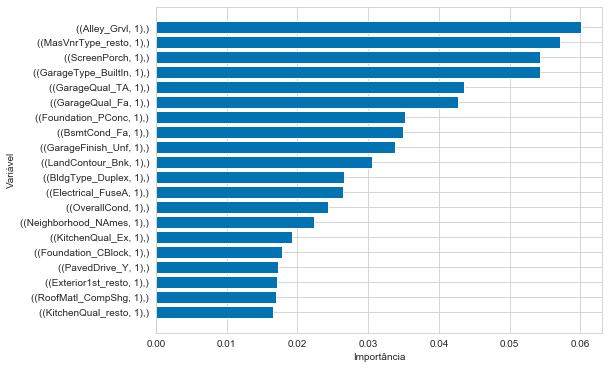

Checando Datasets
Filtrando Features sem Variância
Criando a Expansão em Série
Número de Parâmetros da Expansão: 175
Calculando as Normalizações das Features
Número de Parâmetros: 175
Criando o Baseline Constante
Inicializando os Parâmetros para Fitting
4.236341238021851


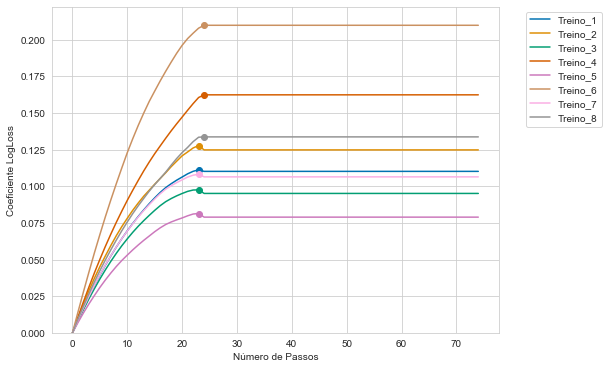

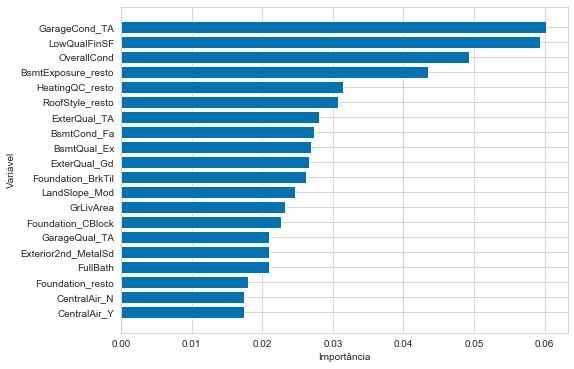

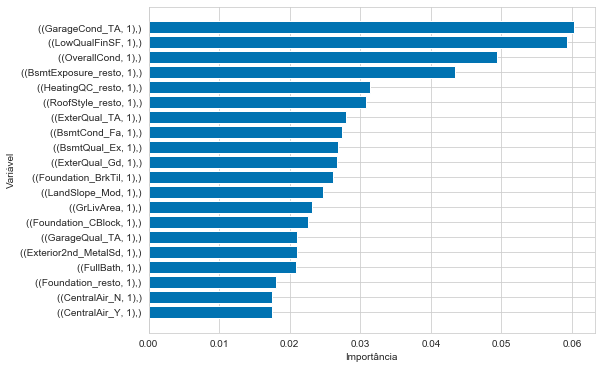

Checando Datasets
Filtrando Features sem Variância
Criando a Expansão em Série
Número de Parâmetros da Expansão: 175
Calculando as Normalizações das Features
Número de Parâmetros: 175
Criando o Baseline Constante
Inicializando os Parâmetros para Fitting
4.7192628383636475


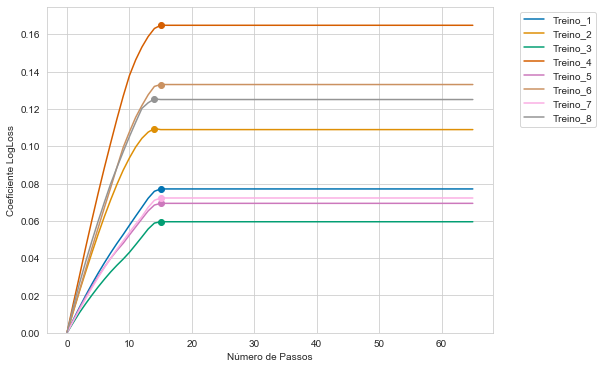

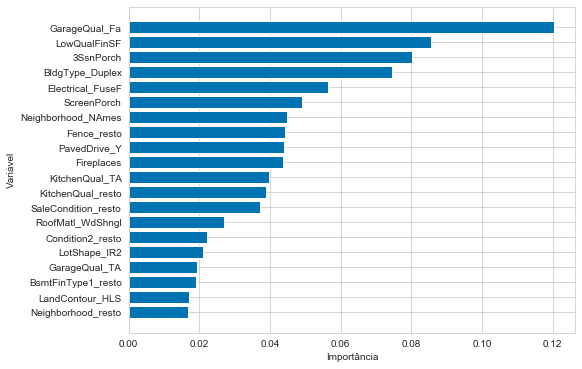

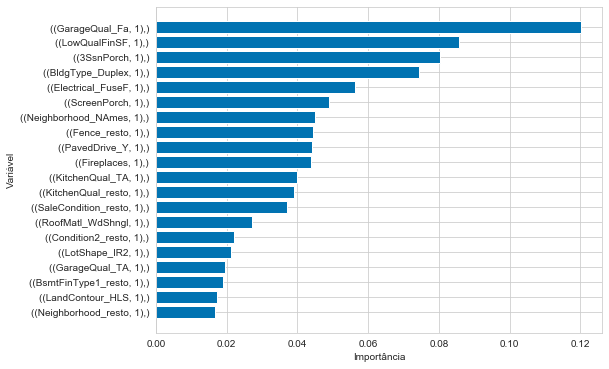

Checando Datasets
Filtrando Features sem Variância
Criando a Expansão em Série
Número de Parâmetros da Expansão: 175
Calculando as Normalizações das Features
Número de Parâmetros: 175
Criando o Baseline Constante
Inicializando os Parâmetros para Fitting
4.092367649078369


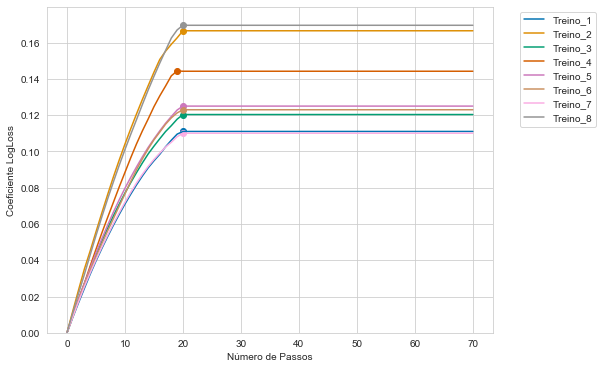

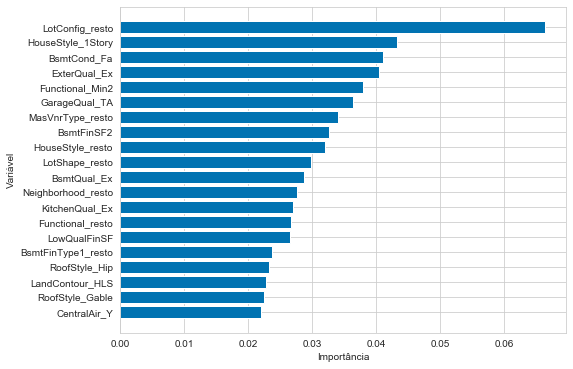

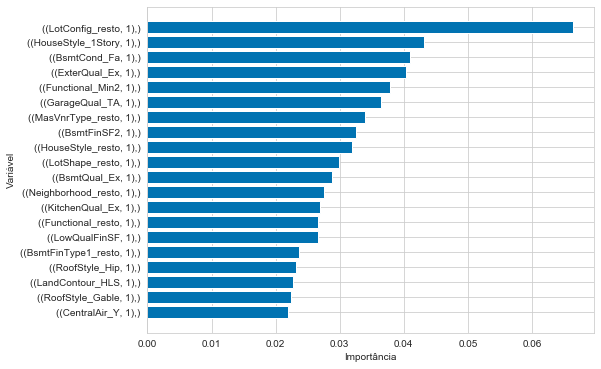

Checando Datasets
Filtrando Features sem Variância
Criando a Expansão em Série
Número de Parâmetros da Expansão: 175
Calculando as Normalizações das Features
Número de Parâmetros: 175
Criando o Baseline Constante
Inicializando os Parâmetros para Fitting
4.320329189300537


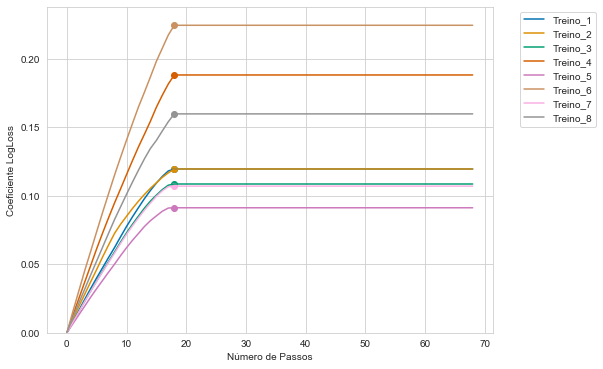

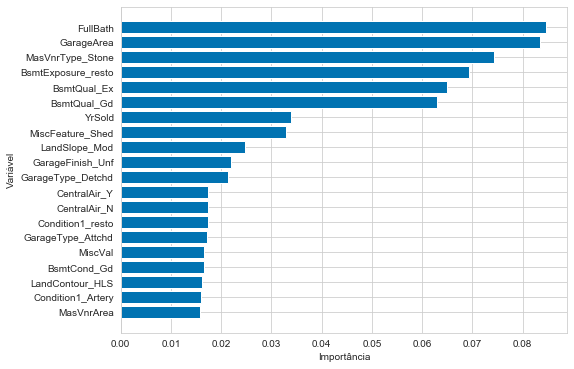

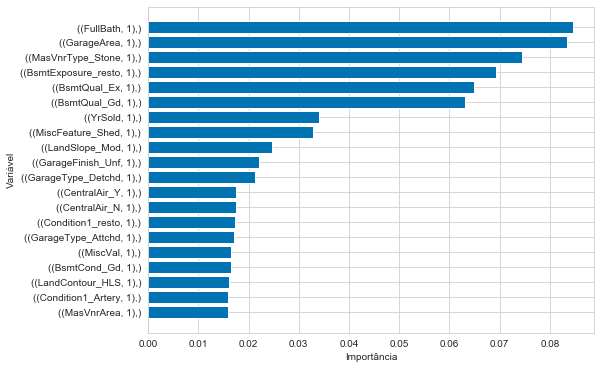

Checando Datasets
Filtrando Features sem Variância
Criando a Expansão em Série
Número de Parâmetros da Expansão: 175
Calculando as Normalizações das Features
Número de Parâmetros: 175
Criando o Baseline Constante
Inicializando os Parâmetros para Fitting
5.10620379447937


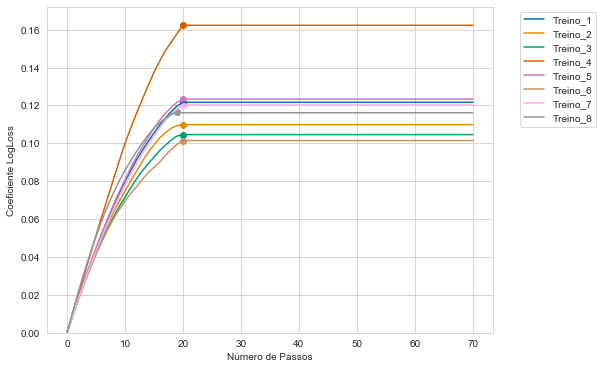

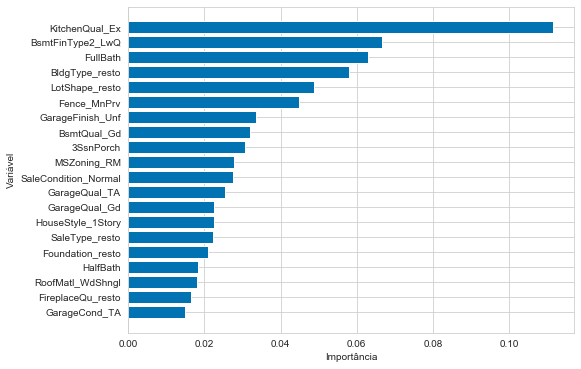

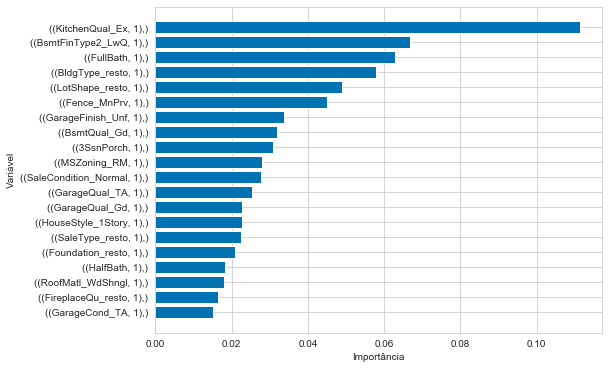

Checando Datasets
Filtrando Features sem Variância
Criando a Expansão em Série
Número de Parâmetros da Expansão: 175
Calculando as Normalizações das Features
Número de Parâmetros: 175
Criando o Baseline Constante
Inicializando os Parâmetros para Fitting
5.422152757644653


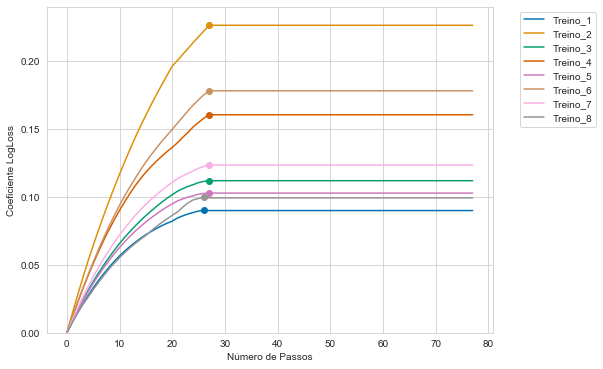

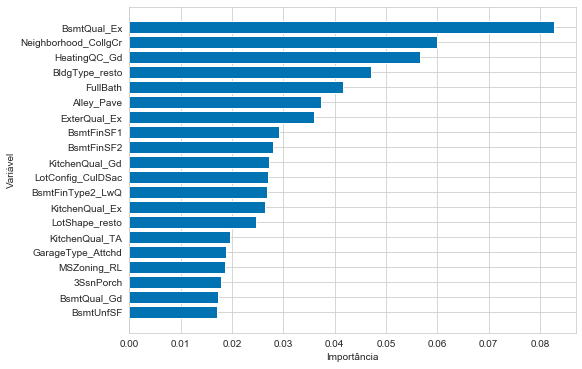

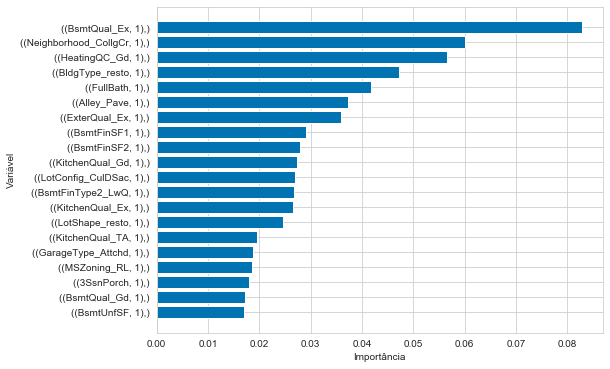

Checando Datasets
Filtrando Features sem Variância
Criando a Expansão em Série
Número de Parâmetros da Expansão: 175
Calculando as Normalizações das Features
Número de Parâmetros: 175
Criando o Baseline Constante
Inicializando os Parâmetros para Fitting
6.118054389953613


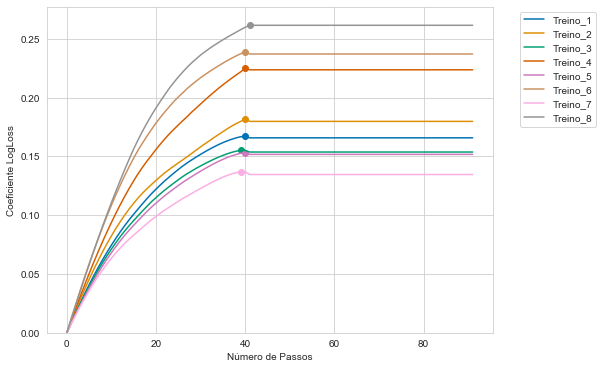

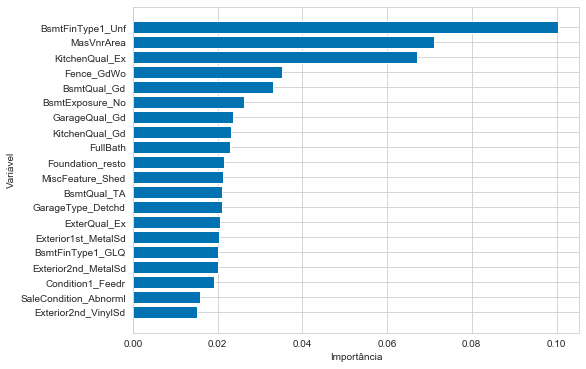

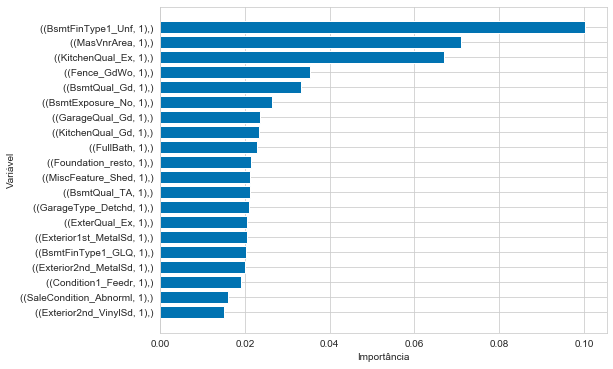

Checando Datasets
Filtrando Features sem Variância
Criando a Expansão em Série
Número de Parâmetros da Expansão: 175
Calculando as Normalizações das Features
Número de Parâmetros: 175
Criando o Baseline Constante
Inicializando os Parâmetros para Fitting
4.6412742137908936


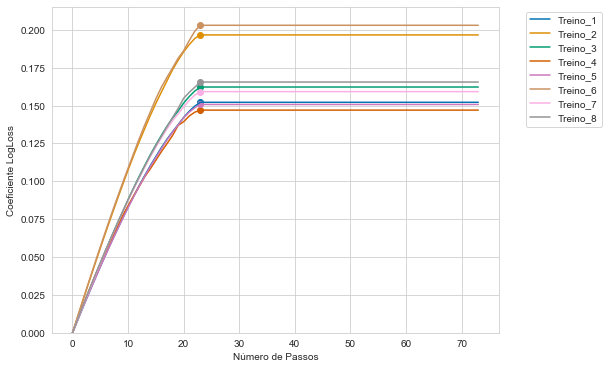

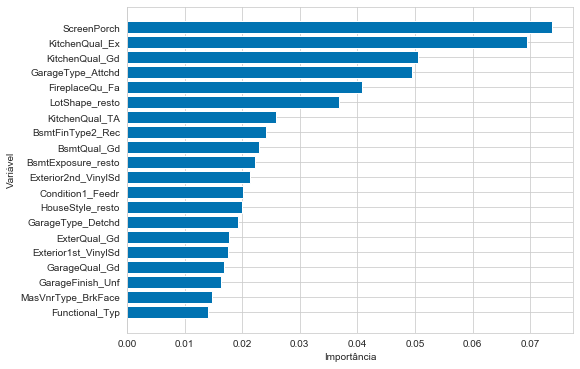

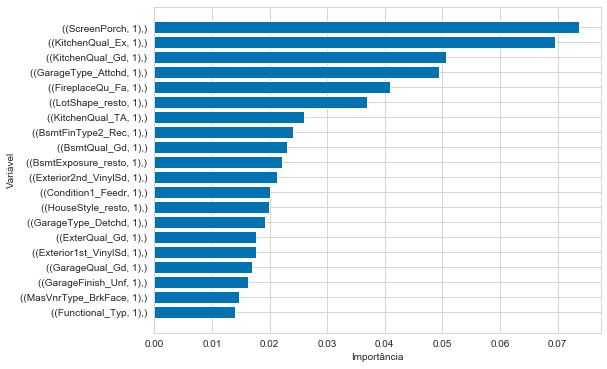

Checando Datasets
Filtrando Features sem Variância
Criando a Expansão em Série
Número de Parâmetros da Expansão: 175
Calculando as Normalizações das Features
Número de Parâmetros: 175
Criando o Baseline Constante
Inicializando os Parâmetros para Fitting
6.91792368888855


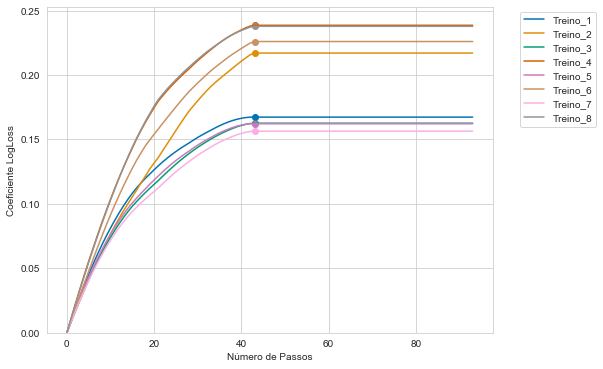

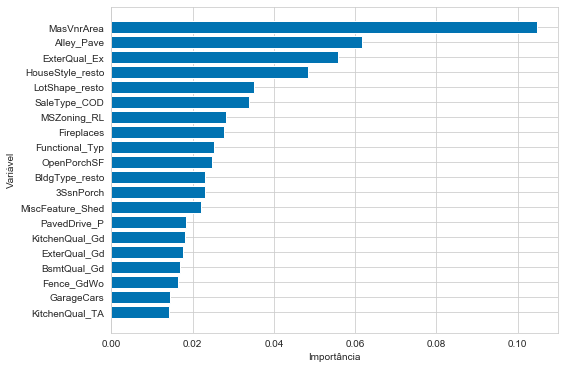

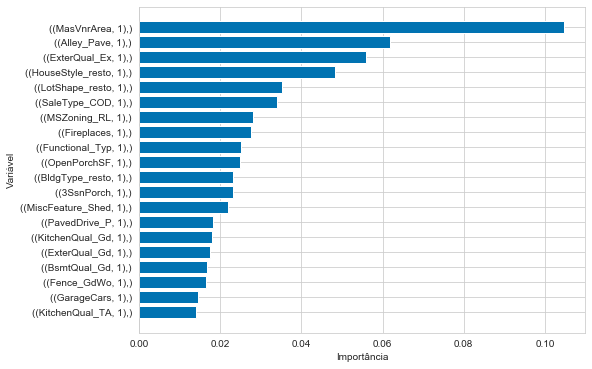

Checando Datasets
Filtrando Features sem Variância
Criando a Expansão em Série
Número de Parâmetros da Expansão: 175
Calculando as Normalizações das Features
Número de Parâmetros: 175
Criando o Baseline Constante
Inicializando os Parâmetros para Fitting
5.63212776184082


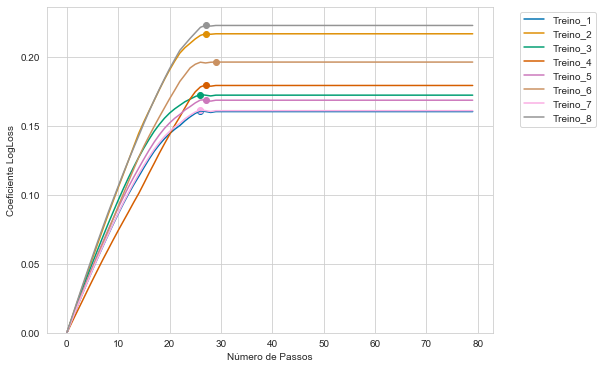

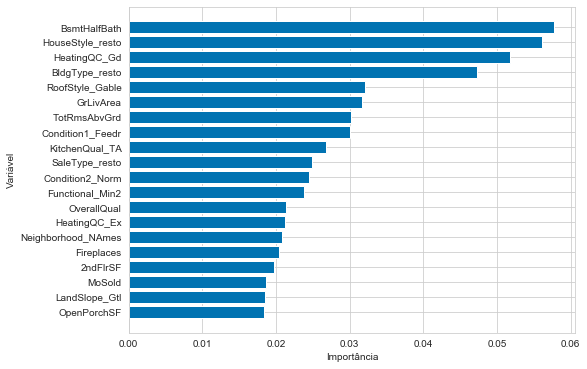

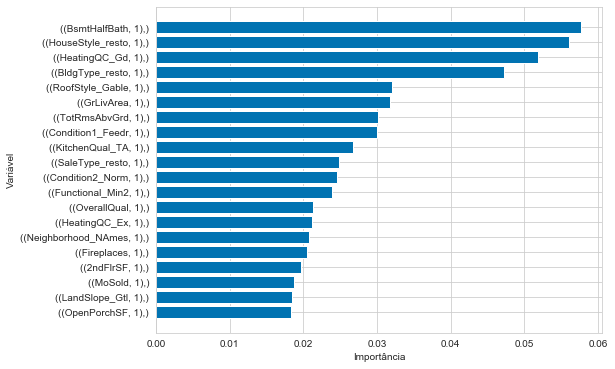

Checando Datasets
Filtrando Features sem Variância
Criando a Expansão em Série
Número de Parâmetros da Expansão: 175
Calculando as Normalizações das Features
Número de Parâmetros: 175
Criando o Baseline Constante
Inicializando os Parâmetros para Fitting
5.011218309402466


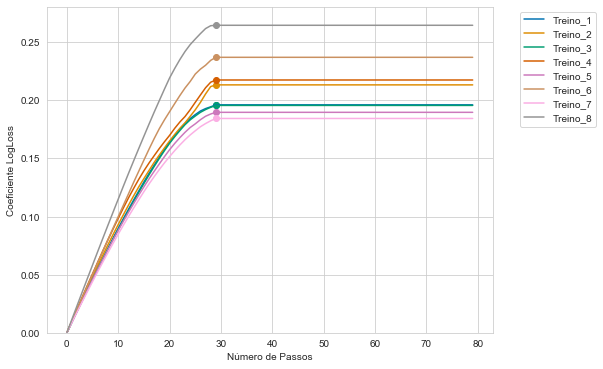

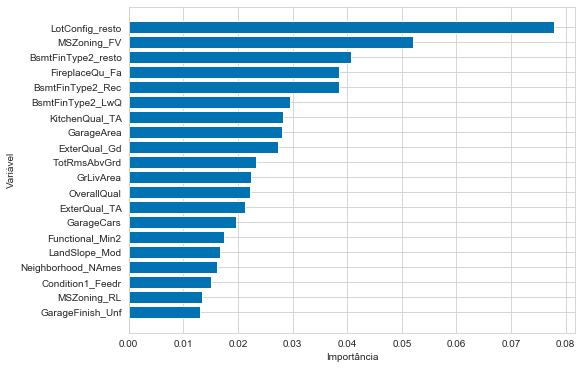

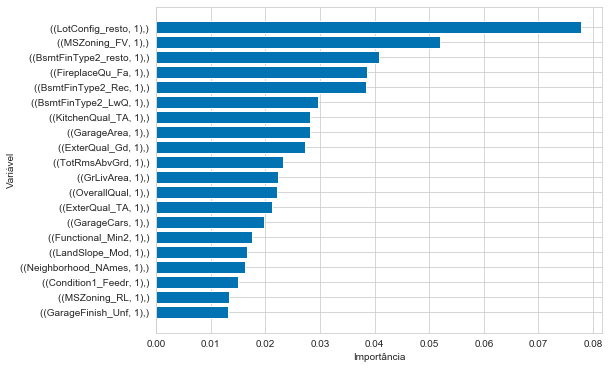

Checando Datasets
Filtrando Features sem Variância
Criando a Expansão em Série
Número de Parâmetros da Expansão: 175
Calculando as Normalizações das Features
Número de Parâmetros: 175
Criando o Baseline Constante
Inicializando os Parâmetros para Fitting
7.126896142959595


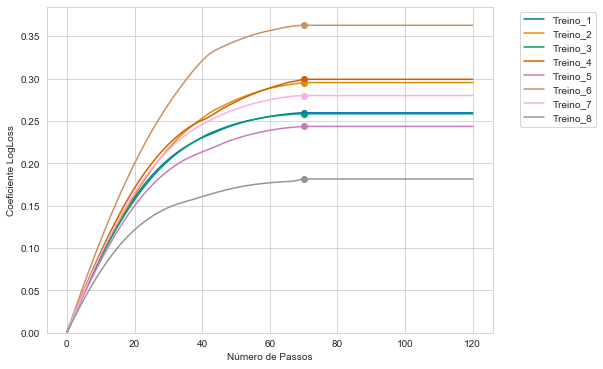

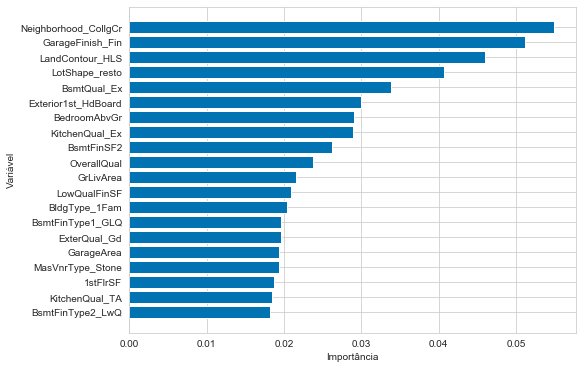

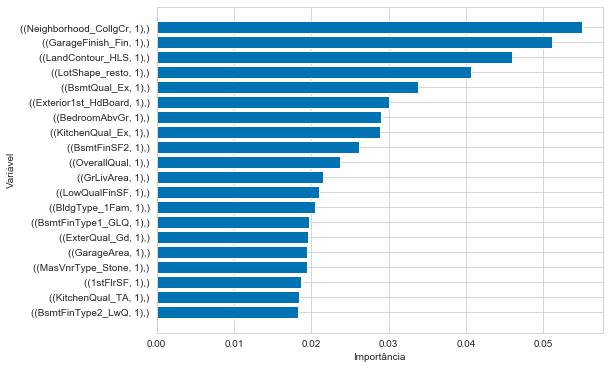

Checando Datasets
Filtrando Features sem Variância
Criando a Expansão em Série
Número de Parâmetros da Expansão: 175
Calculando as Normalizações das Features
Número de Parâmetros: 175
Criando o Baseline Constante
Inicializando os Parâmetros para Fitting
65.22687888145447


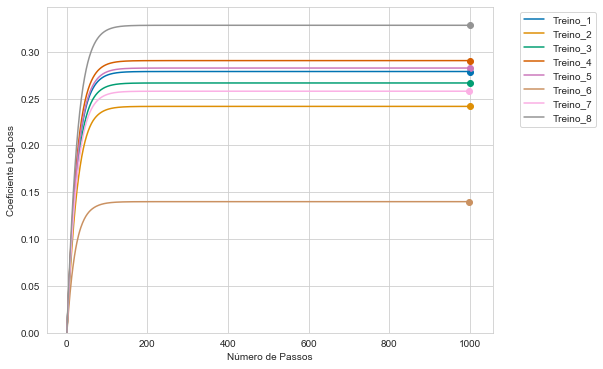

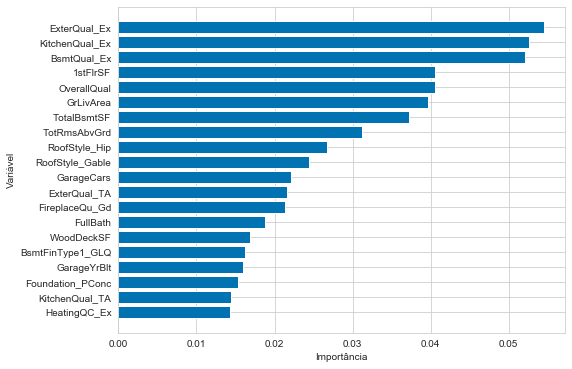

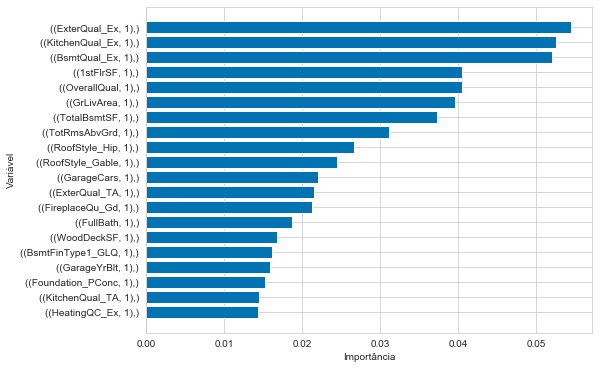

In [26]:
lista_clf = []

for k in range(0, N):

    dict_Xy = {}

    i = 0
    for par in lista_splits:
        df_treino = df_intermed.iloc[par[0]]
        df_val = df_intermed.iloc[par[1]]

        df_treino_t = tratador.aplica_transformacao_ohe(df_treino, usar_ponto_medio = True)
        df_val_t = tratador.aplica_transformacao_ohe(df_val, usar_ponto_medio = True)
        
        df_treino_t[alvo] = (discretizador.intervalos.aplica_discretizacao(df_treino_t['SalePrice'].values, usar_ponto_medio = False) == k).astype(int)
        df_val_t[alvo] = (discretizador.intervalos.aplica_discretizacao(df_val_t['SalePrice'].values, usar_ponto_medio = False) == k).astype(int)
        
        dict_Xy.update({'Treino_' + str(2*i + 1): (df_treino_t.drop(colunas_id, axis = 1).drop(alvo, axis = 1), df_treino_t[alvo]),
                   'Treino_' + str(2*i + 2): (df_val_t.drop(colunas_id, axis = 1).drop(alvo, axis = 1), df_val_t[alvo])})

        i = i + 1
        
    t = time.time()

    clf = lrn.SeriesMultiGradientClassifier()
    clf.setup_datasets(dict_Xy, laurent = False, ordem = 1, apenas_interacoes = False)
    clf.setup_optimizer(alpha = 0.01, epsilon = 1e-6, early_stop = 50, filtro_atualizacao_thetas = True)
    clf.fit(num_passos = 1000, verbose = 0, plot = False)

    print(time.time() - t)

    clf.grafico_vies_variancia(ymin = 0)
    clf.grafico_importancias(num_vars = 20)
    clf.grafico_importancias_termos(num_vars = 20)
    
    lista_clf.append(clf)

In [27]:
df_intermed_aval = df_intermed.copy()
df_teste_aval = df_teste.copy()

for k in range(0, N):
    df_intermed_aval['Alvo_' + str(k)] = lista_clf[k].predict_proba(df_intermed_t.drop(colunas_id, axis = 1).drop(alvo, axis = 1))[:, 1]
    df_teste_aval['Alvo_' + str(k)] = lista_clf[k].predict_proba(df_teste_t.drop(colunas_id, axis = 1).drop(alvo, axis = 1))[:, 1]

soma_intermed = df_intermed_aval[['Alvo_' + str(k) for k in range(0, N)]].sum(axis = 1)
soma_teste = df_teste_aval[['Alvo_' + str(k) for k in range(0, N)]].sum(axis = 1)
for k in range(0, N):
    df_intermed_aval['Alvo_' + str(k)] = df_intermed_aval['Alvo_' + str(k)]/soma_intermed
    df_teste_aval['Alvo_' + str(k)] = df_teste_aval['Alvo_' + str(k)]/soma_teste

Treino       Teste
QTD               1200.0       290.0
Soma_Alvo    210000000.0  52000000.0
Soma_Pred    210000000.0  52000000.0
Media_Alvo      180000.0    180000.0
Media_Pred      180000.0    180000.0
KS                 0.037        0.07
Coef_KS              0.7        0.48
Coef_KS_ref          0.7        0.56

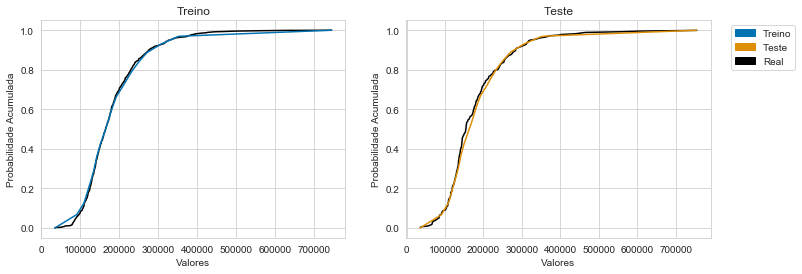

In [28]:
dict_dfs = {'Treino': df_intermed_aval, 'Teste': df_teste_aval}
avaliacaorgs = aml.AvaliaDatasetsDistribuicaoProbabilidade(dict_dfs, alvo, ['Alvo_' + str(k) for k in range(0, N)], 
                                                           discretizador,
                                                           num_div = 10,
                                                           num_cat = 5,
                                                           unit = 'M')

display(avaliacaorgs.valor_metricas(alga_signif = 2, conv_str = True))

avaliacaorgs.grafico_distribuicao_acumulada()

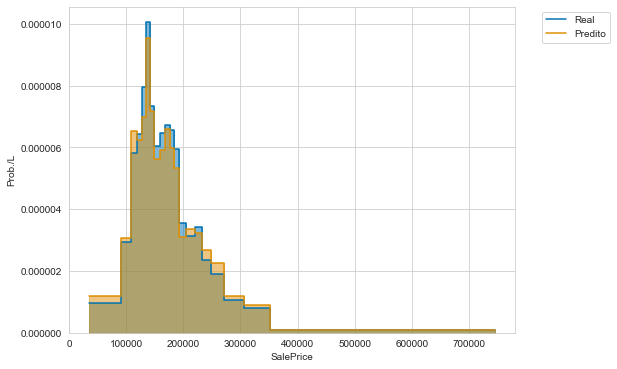

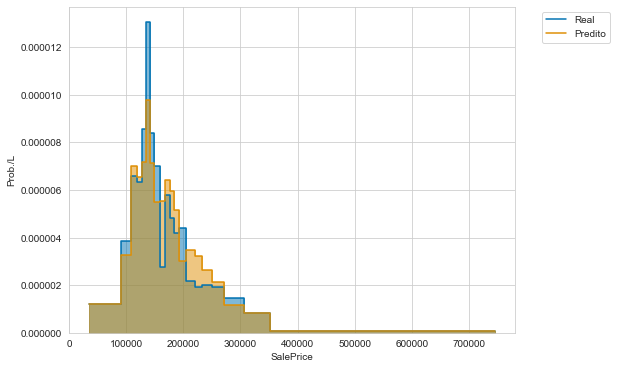

In [31]:
paleta_cores = sns.color_palette("colorblind")
with sns.axes_style("whitegrid"):
    fig, axs = plt.subplots(1, 1, figsize = [8, 6])
    
    x, y = discretizador.curva_distribuicao_probabilidade(discretizador.calcula_probabilidades(df_intermed[alvo].values))
    axs.plot(x, y, color = paleta_cores[0], label = 'Real')
    axs.fill_between(x, y, color = paleta_cores[0], alpha = 0.5)

    x, y = discretizador.curva_distribuicao_probabilidade(df_intermed_aval[['Alvo_' + str(k) for k in range(0, N)]].values)
    axs.plot(x, y, color = paleta_cores[1], label = 'Predito')
    axs.fill_between(x, y, color = paleta_cores[1], alpha = 0.5)
    
    axs.set_ylim(bottom = 0.0)
    axs.set_xlabel(alvo)
    axs.set_ylabel('Prob./L')
    axs.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.show()

paleta_cores = sns.color_palette("colorblind")
with sns.axes_style("whitegrid"):
    fig, axs = plt.subplots(1, 1, figsize = [8, 6])
    
    x, y = discretizador.curva_distribuicao_probabilidade(discretizador.calcula_probabilidades(df_teste_aval[alvo].values))
    axs.plot(x, y, color = paleta_cores[0], label = 'Real')
    axs.fill_between(x, y, color = paleta_cores[0], alpha = 0.5)

    x, y = discretizador.curva_distribuicao_probabilidade(df_teste_aval[['Alvo_' + str(k) for k in range(0, N)]].values)
    axs.plot(x, y, color = paleta_cores[1], label = 'Predito')
    axs.fill_between(x, y, color = paleta_cores[1], alpha = 0.5)
    
    axs.set_ylim(bottom = 0.0)
    axs.set_xlabel(alvo)
    axs.set_ylabel('Prob./L')
    axs.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.show()

from functools import reduce

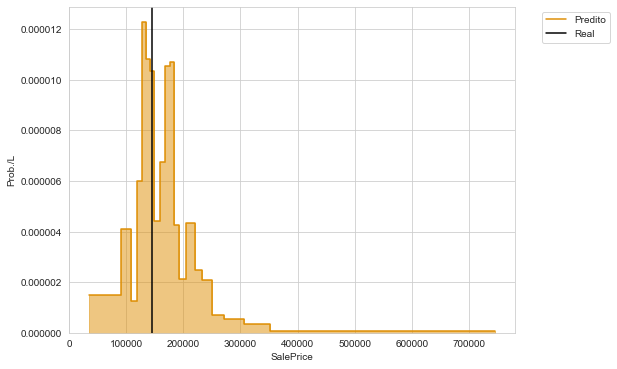

In [43]:
i = 7

paleta_cores = sns.color_palette("colorblind")
with sns.axes_style("whitegrid"):
    fig, axs = plt.subplots(1, 1, figsize = [8, 6])

    x, y = discretizador.curva_distribuicao_probabilidade(df_teste_aval[['Alvo_' + str(k) for k in range(0, N)]].iloc[i].values)
    axs.plot(x, y, color = paleta_cores[1], label = 'Predito')
    axs.fill_between(x, y, color = paleta_cores[1], alpha = 0.5)

    y = df_teste_aval[alvo].iloc[i]
    axs.axvline(y, color = 'black', label = 'Real')
    
    axs.set_ylim(bottom = 0.0)
    axs.set_xlabel(alvo)
    axs.set_ylabel('Prob./L')
    axs.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.show()